# BIL545 · Proje 1 · Vizeye kadarki konular (2.–7. haftalar)
**Veri Madenciliğinde İleri Konular · 2026–2027 Güz** · **Vize notu** · Teslim ve sunum: **8. hafta**

Bu defter projenin şablonudur. Grubunuz defteri kendi Drive'ına kopyalar (**Dosya → Drive'a kopya kaydet**), doldurur ve **iki yere** yükler: GitHub deposundaki `proje1/` klasörüne ve STIX'teki ödev alanına. Bütün yazılı cevaplar bu defterin metin hücrelerindedir; ayrı bir rapor yoktur.

**Kapsam grup tipine göre:** 1–3 kişilik gruplar Bölüm 1–3'ü, 4 kişilik gruplar ek olarak Ek paket 1'i, 5 kişilik gruplar Ek paket 1 ve 2'yi yapar. Grubunuzun yapmadığı ek paket bölümlerini silin. Defterin sonundaki **katkı beyanı puanlanır**; sunumda her üye en az bir alt başlığı anlatır.

**Teslimden önce:** Çalışma zamanını sıfırlayıp **Çalışma Zamanı → Tümünü çalıştır** ile defteri baştan sona hatasız çalıştırın.

**Puanlama:** Başarım puanlanmaz. Her bölüm kurulumun doğruluğu (%30), kararların gerekçesi (%25), dürüst raporlama (%25), yorum (%15) ve teknik düzene (%5) göre puanlanır. Ayrıntılar: *Proje 1 ve Proje 2 Yönergesi*.

## Grup bilgisi

| | Ad Soyad | Öğrenci no |
|---|---|---|
| Tek kişi | **[DOLDURULACAK]** | **[DOLDURULACAK]** |

- **Grup adı:** Bireysel çalışma
- **Grup tipi:** 1 kişi — yalnızca Bölüm 1, 2 ve 3
- **Araştırma sorusu:** Bir e-ticaret oturumunun kaydedilmiş davranışsal özellikleri, satın almayla sonuçlanan oturumları güvenilir biçimde ayırt etmede ne kadar etkilidir?

**Not:** Bu soru oturum verilerindeki sonuçla ilişkileri inceler; oturum tamamlanmadan yapılan canlı tahmin iddiasında bulunmak için özelliklerin hangi aşamada bilindiği ayrıca değerlendirilmelidir.


## Hazırlık

In [ ]:
import sys, numpy as np, pandas as pd, sklearn
SEED = 42
np.random.seed(SEED)
print("Python      ", sys.version.split()[0]); print("numpy       ", np.__version__)
print("pandas      ", pd.__version__);          print("scikit-learn", sklearn.__version__)

Python       3.13.18
numpy        2.4.6
pandas       2.2.3
scikit-learn 1.6.1


### Veriyi yükleme

- **Kaynak:** UCI Machine Learning Repository — [Online Shoppers Purchasing Intention Dataset](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)
- **Lisans:** CC BY 4.0 (veri seti sayfasında doğrulanacak)
- **İndirme / yükleme adımı:** `ucimlrepo` ile UCI veri kümesi ID 468 otomatik indirilir. Ham veri GitHub'a yüklenmez.
- **Hedef değişken:** `Revenue` (satın alma ile sonuçlanma)
- **Kontrol:** Başarıyla indirildikten sonra boyut, veri türleri, hedef dağılımı ve tekrarlar incelenir.


In [ ]:
# UCI 468 veri kümesini kaynağından otomatik getirir.
# Colab internete bağlı olmalıdır; veri dosyası GitHub'a yüklenmez.
%pip -q install ucimlrepo
from ucimlrepo import fetch_ucirepo

uci_online_shoppers = fetch_ucirepo(id=468)
X = uci_online_shoppers.data.features.copy()
y_source = uci_online_shoppers.data.targets.copy()
y = y_source['Revenue'] if 'Revenue' in y_source.columns else y_source.iloc[:, 0]
y = y.astype(bool)
df = X.copy()
df['Revenue'] = y.to_numpy()

print('Satır x sütun:', df.shape)
print('Özellik sayısı:', X.shape[1])
print('Hedef değişken dağılımı:')
print(df['Revenue'].value_counts(dropna=False))
print('Hedef yüzdesi:')
print(df['Revenue'].value_counts(normalize=True, dropna=False).mul(100).round(2))
display(df.head())


Satır x sütun: (12330, 18)
Özellik sayısı: 17
Hedef değişken dağılımı:
Revenue
False    10422
True      1908
Name: count, dtype: int64
Hedef yüzdesi:
Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


# Bölüm 1 · Veri, ön işleme ve sızıntı *(ağırlık 30)*
**Makale:** Kaufman vd. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM TKDD*, 6(4).

**Okuma notu (3–4 cümle):** …

### 1.1 Veri künyesi

| Soru | Cevap |
|---|---|
| Veri seti | **Online Shoppers Purchasing Intention Dataset**, UCI Machine Learning Repository (ID: 468) |
| Kim, hangi amaçla topladı? | UCI kaynak künyesinde veri setinin yaratıcıları **C. Sakar ve Yomi Kastro** olarak belirtilir. Amaç, web oturumlarının davranışsal bilgileriyle satın alma sonucunun incelenmesi ve tahminidir. |
| Hangi dönemi kapsıyor? | UCI açıklamasına göre **bir yıllık dönem**; oturumlar bu dönemde farklı kullanıcılara aittir. Kesin başlangıç/bitiş tarihleri kaynak sayfasında verilmemiştir; 2018 veri setinin UCI'ye bağış yılıdır, veri toplama dönemi olarak alınmaz. |
| Veri birimi | Bir satır, bir **e-ticaret oturumu**. Veri setinde 12.330 oturum, 17 girdi özelliği ve 1 hedef vardır. |
| Hedef gerçek olgu mu, vekil mi? | `Revenue`, oturumun alışverişle sonuçlanıp sonuçlanmadığının kaydıdır (gözlenen ikili sonuç). Daha sonraki müşteri değeri veya satın alma niyeti gibi kavramların doğrudan ölçümü değildir. |
| Kimler eksik temsil ediliyor olabilir? | Satın alan oturumlar azınlıktadır (%15,47). Ayrıca veri tek kaynaktan geldiğinden farklı mağaza, ülke, cihaz veya demografik kesimlere genellenebilirlik doğrulanmamıştır; kaynakta demografik kapsam ayrıntısı yoktur. |
| Lisans | **CC BY 4.0** — kaynak göstererek kullanım ve uyarlama mümkündür. |
| Kaynak / DOI | https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset · https://doi.org/10.24432/C5F88Q |

**Bilimsel not:** Oturum boyunca değişen özelliklerin (ör. `ProductRelated_Duration`, `ExitRates`, `PageValues`) hangi anda bilindiği, olası bir erken tahmin senaryosunda ayrıca incelenmelidir. Bu sütunlar sırf hedefle güçlü ilişkili oldukları için otomatik olarak "sızıntı" diye etiketlenemez.


In [ ]:
# UCI veri setinin resmî değişken künyesini görüntüle.
# Veri künyesi kaynak metniyle birlikte değerlendirilmelidir.
print("Kaynak:", "https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset")
print("Veri birimi: oturum")
print("Girdi özelliği sayısı:", X.shape[1])
print("Gözlem sayısı:", len(df))
print("Hedef değişken:", y.name)
print("Hedef sınıflarının oranı (%):")
display(df["Revenue"].value_counts(normalize=True).mul(100).round(2).rename("Yüzde (%)").to_frame())
print("UCI değişken açıklamaları:")
display(uci_online_shoppers.variables)


Kaynak: https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset
Veri birimi: oturum
Girdi özelliği sayısı: 17
Gözlem sayısı: 12330
Hedef değişken: Revenue
Hedef sınıflarının oranı (%):


,Yüzde (%)
Revenue,
False,84.53
True,15.47


UCI değişken açıklamaları:


,name,role,type,demographic,description,units,missing_values
0,Administrative,Feature,Integer,None,None,None,no
1,Administrative_Duration,Feature,Integer,None,None,None,no
2,Informational,Feature,Integer,None,None,None,no
3,Informational_Duration,Feature,Integer,None,None,None,no
4,ProductRelated,Feature,Integer,None,None,None,no
5,ProductRelated_Duration,Feature,Continuous,None,None,None,no
6,BounceRates,Feature,Continuous,None,None,None,no
7,ExitRates,Feature,Continuous,None,None,None,no
8,PageValues,Feature,Integer,None,None,None,no
9,SpecialDay,Feature,Integer,None,None,None,no


**Yorum — 1.1 Veri künyesi**

Veri seti 12.330 e-ticaret oturumundan oluşmaktadır. 10.422 oturum (%84,53) satın almayla sonuçlanmazken 1.908 oturum (%15,47) satın almayla sonuçlanmıştır. Bu nedenle veri kümesi sınıf dengesizliği içermektedir. Çoğunluk sınıfını sürekli tahmin eden bir yaklaşımın doğruluğu %84,53 olacağından, sonraki sınıflandırma modelleri yalnızca accuracy ile değerlendirilmemelidir.

UCI kaynağına göre kayıtlar bir yıllık dönemdendir, ancak kesin tarih aralığı belirtilmemiştir. `Revenue` alışveriş sonucunu temsil eder; kullanıcıların öznel satın alma niyetini doğrudan ölçmez. Kullanıcı veya mağaza çeşitliliğine ilişkin yeterli demografik ayrıntı bulunmadığından sonuçlar her e-ticaret ortamına doğrudan genellenemez.


### 1.2 Keşifsel veri analizi

Bu hücrede **verinin boyutunu, saklama ve ölçüm türlerini, sınıf dağılımını, yinelenen satırları** ve her girdi özelliği için **veri tipi, eksik oranı, benzersiz değer sayısı ve sıfır oranını** inceleyin.

**Önemli ayrım:** `OperatingSystems`, `Browser`, `Region` ve `TrafficType` tam sayı olarak saklansa da sayısal büyüklük değil **kategorik kod** olarak yorumlanır. `Month`, `VisitorType` ve `Weekend` de kategoriktir. Sıfır oranını yorumlamak sayısal ölçümler için anlamlıdır.

Şüpheli/görev zamanlamasına bağlı dikkat gerektiren değişkenler: `PageValues`, `ExitRates`, `BounceRates` ve oturum boyunca biriken süreler. Bunlar otomatik olarak çıkarılmayacak; önce özelliklerin hangi anda mevcut olduğu araştırılacaktır.


Boyut (oturum x tüm sütunlar): (12330, 18)
Girdi özellikleri: 17
Tamamen aynı satırlar (hedef dahil): 125
Aynı girdi özelliklerine sahip satırlar (hedef hariç): 125
Gerçek NaN sayısı (tüm tablo): 0
Bellek kullanımı (MB): 2.718


,Öznitelik,Saklama tipi,Ölçek türü,Eksik (%),Farklı değer,Sıfır (%)
0,Administrative,int64,Sayısal / sayım,0.0,27,46.78
1,Administrative_Duration,float64,Sayısal / sürekli veya oran,0.0,3335,47.88
2,Informational,int64,Sayısal / sayım,0.0,17,78.66
3,Informational_Duration,float64,Sayısal / sürekli veya oran,0.0,1258,80.49
4,ProductRelated,int64,Sayısal / sayım,0.0,311,0.31
5,ProductRelated_Duration,float64,Sayısal / sürekli veya oran,0.0,9551,6.12
6,BounceRates,float64,Sayısal / sürekli veya oran,0.0,1872,44.75
7,ExitRates,float64,Sayısal / sürekli veya oran,0.0,4777,0.62
8,PageValues,float64,Sayısal / sürekli veya oran,0.0,2704,77.86
9,SpecialDay,float64,Sayısal / sürekli veya oran,0.0,6,89.85


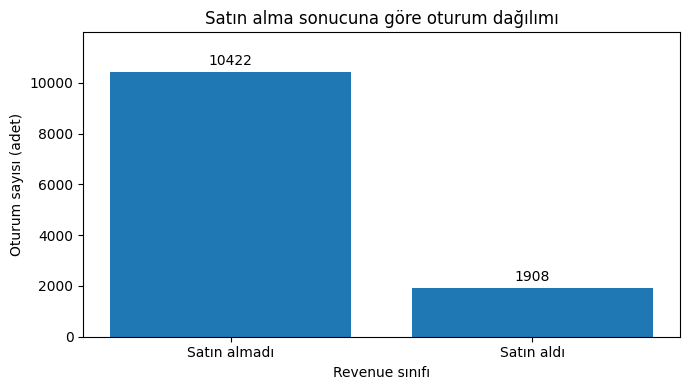

Grafik yorumu: Satın alan sınıfı belirgin şekilde daha azdır;
yalnızca doğruluk ölçütüne bakmak yanıltıcı olabilir.

Month (kategori sayımları):


,Oturum sayısı
Month,
May,3364
Nov,2998
Mar,1907
Dec,1727
Oct,549
Sep,448
Aug,433
Jul,432
June,288



VisitorType (kategori sayımları):


,Oturum sayısı
VisitorType,
Returning_Visitor,10551
New_Visitor,1694
Other,85



Weekend (kategori sayımları):


,Oturum sayısı
Weekend,
False,9462
True,2868



Zamanlama / olası sızıntı için ayrıca denetlenecek özellikler:
['PageValues', 'ExitRates', 'BounceRates', 'ProductRelated_Duration']
Not: Bu liste sızıntının kanıtı değil, denetim hipotezidir.

=== 1.2 KISA KONTROL ÖZETİ ===
Tam yinelenen satırlar: 125
Girdi özellikleri aynı satırlar: 125
Toplam eksik hücre: 0
Eksik değerli özellikler: []
En fazla farklı değer içeren 5 özellik:


,Öznitelik,Farklı değer
5,ProductRelated_Duration,9551
7,ExitRates,4777
1,Administrative_Duration,3335
8,PageValues,2704
6,BounceRates,1872


Sıfır oranı en yüksek 5 sayısal özellik:


,Öznitelik,Sıfır (%)
9,SpecialDay,89.85
3,Informational_Duration,80.49
2,Informational,78.66
8,PageValues,77.86
1,Administrative_Duration,47.88


In [ ]:
import matplotlib.pyplot as plt

# 1.2.1: Temel veri denetimi
print("Boyut (oturum x tüm sütunlar):", df.shape)
print("Girdi özellikleri:", X.shape[1])
print("Tamamen aynı satırlar (hedef dahil):", int(df.duplicated().sum()))
print("Aynı girdi özelliklerine sahip satırlar (hedef hariç):", int(X.duplicated().sum()))
print("Gerçek NaN sayısı (tüm tablo):", int(df.isna().sum().sum()))
print("Bellek kullanımı (MB):", round(df.memory_usage(deep=True).sum() / (1024 ** 2), 3))

# 1.2.2: Saklama tipi ile analizdeki ölçüm türünü ayır.
nominal_columns = {
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
}
count_columns = {"Administrative", "Informational", "ProductRelated"}

rows = []
for col in X.columns:
    ser = X[col]
    is_category = col in nominal_columns
    if is_category:
        scale = "Kategorik / nominal"
    elif col in count_columns:
        scale = "Sayısal / sayım"
    else:
        scale = "Sayısal / sürekli veya oran"
    has_meaningful_zero = (not is_category) and pd.api.types.is_numeric_dtype(ser)
    zero_pct = round(float(ser.eq(0).mean() * 100), 2) if has_meaningful_zero else np.nan
    rows.append({
        "Öznitelik": col,
        "Saklama tipi": str(ser.dtype),
        "Ölçek türü": scale,
        "Eksik (%)": round(float(ser.isna().mean() * 100), 2),
        "Farklı değer": int(ser.nunique(dropna=True)),
        "Sıfır (%)": zero_pct,
    })
profile_table = pd.DataFrame(rows)
display(profile_table)

# 1.2.3: Hedef değişken dağılımı
counts = df["Revenue"].value_counts().reindex([False, True], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["Satın almadı", "Satın aldı"], counts.to_numpy())
ax.bar_label(bars, padding=3)
ax.set_xlabel("Revenue sınıfı")
ax.set_ylabel("Oturum sayısı (adet)")
ax.set_title("Satın alma sonucuna göre oturum dağılımı")
ax.set_ylim(0, max(counts) * 1.15)
fig.tight_layout()
plt.show()
print("Grafik yorumu: Satın alan sınıfı belirgin şekilde daha azdır;")
print("yalnızca doğruluk ölçütüne bakmak yanıltıcı olabilir.")

# 1.2.4: Kategorik sütunları ve riskli olabilecek özellikleri görünür kıl.
for col in ["Month", "VisitorType", "Weekend"]:
    print(f"\n{col} (kategori sayımları):")
    display(X[col].value_counts(dropna=False).rename("Oturum sayısı").to_frame())

print("\nZamanlama / olası sızıntı için ayrıca denetlenecek özellikler:")
print(["PageValues", "ExitRates", "BounceRates", "ProductRelated_Duration"])
print("Not: Bu liste sızıntının kanıtı değil, denetim hipotezidir.")

# 1.2.5: Ekran görüntüsü yerine kısa ve doğrulanabilir özet
print("\n=== 1.2 KISA KONTROL ÖZETİ ===")
print("Tam yinelenen satırlar:", int(df.duplicated().sum()))
print("Girdi özellikleri aynı satırlar:", int(X.duplicated().sum()))
print("Toplam eksik hücre:", int(df.isna().sum().sum()))
print("Eksik değerli özellikler:", profile_table.loc[profile_table["Eksik (%)"] > 0, "Öznitelik"].tolist())
print("En fazla farklı değer içeren 5 özellik:")
display(profile_table.sort_values("Farklı değer", ascending=False)[["Öznitelik", "Farklı değer"]].head(5))
print("Sıfır oranı en yüksek 5 sayısal özellik:")
display(profile_table.dropna(subset=["Sıfır (%)"]).sort_values("Sıfır (%)", ascending=False)[["Öznitelik", "Sıfır (%)"]].head(5))


**Yorum — 1.2 Keşifsel analiz (Colab çıktılarıyla doğrulanmıştır)**

Veri setinde **12.330 oturum, 17 girdi özelliği ve bir ikili hedef** bulunmaktadır. Satın alma ile sonuçlanan oturumlar 1.908 (%15,47), diğerleri 10.422 (%84,53) adettir. Bu sınıf dengesizliği nedeniyle yalnızca accuracy yerine balanced accuracy, F1 veya average precision gibi ölçütlerin de raporlanması gerekir.

- **Yinelenen kayıtlar:** Tamamen aynı **125 satır** vardır; hedef hariç girdileri aynı olan satırların sayısı da **125**'tir. Bu yaklaşık **%1,01** oranındadır. Yinelenen satırların gerçek tekrarlayan oturumları mı, yoksa kayıt tekrarlarını mı temsil ettiği mevcut bilgilerden anlaşılamaz; bu nedenle veri keşfi sırasında sessizce silinmemiştir. Sınıflandırma aşamasında bu satırların çapraz doğrulamayı iyimser kılmaması için grup bazlı ayırma veya yinelenen kayıtları çıkarma duyarlılık kontrolü yapılacaktır.
- **Eksik değerler:** Gerçek veri tablosundaki toplam eksik hücre **0**'dır; hiçbir girdi özelliğinde gözlenen NaN bulunmamaktadır. Sıfır değerleri eksiklik sayılmamıştır.
- **Yüksek farklı değer sayısı:** `ProductRelated_Duration` 9.551 farklı değer içerir; bu sürekli bir ölçüm olduğundan yüksek benzersiz değer sayısı tek başına kategorik kodlama gerektirmez. Kategorik değişkenlerden `TrafficType` (**20 kategori**) ve `Browser` (**13 kategori**) farklı kodlama stratejileri için adaydır.
- **Sıfırların yoğunluğu:** Sayısal ölçümlerde `SpecialDay` **%89,85**, `Informational_Duration` **%80,49**, `Informational` **%78,66**, `PageValues` **%77,86** sıfır değer içerir. Bu, otomatik olarak eksik veri anlamına gelmez.
- **Oturum profili:** En fazla oturum Mayıs (**3.364**) ve Kasım (**2.998**) aylarındadır. `Returning_Visitor` sınıfında **10.551** kayıt vardır. Oturumların **9.462**'si hafta içi, **2.868**'i hafta sonudur. Oturum sayısı tek başına satın alma oranına dair yorum yapmaya yetmez.
- **Zamanlamaya bağlı sızıntı riski:** `PageValues`, `ExitRates`, `BounceRates` ve oturum boyunca biriken süreler erken tahmin amacıyla kullanıldığında özelliklerin hangi anda bilindiği özellikle incelenmelidir. Bu sütunlar kendiliğinden sızıntı kanıtı değildir.

**Sınırlılık:** Tam tekrarlanan kayıtların kaynağı ve hangi özelliklerin oturumun hangi anında oluştuğu doğrudan bu tablodan belirlenememektedir; kararlar sonraki deneylerle açıkça gerekçelendirilecektir.


### 1.3 Eksiklik analizi — gerçek eksiklik yoksa kontrollü deney

Yönergede eksik kodlarının NaN'a çevrilmesi, eksiklik deseninin incelenmesi, iki sütunda MCAR/MAR/MNAR mekanizmalarının tartışılması ve `SimpleImputer(add_indicator=True)` etkisinin ölçülmesi istenir.

**Veriye özgü durum:** UCI 468'in incelenen sürümünde gerçek eksik hücre sayısı **0**'dır. Bu durumda gerçek veriden "en çok eksiği olan iki sütun" seçmek veya mekanizma türünü istatistiksel olarak tahmin etmek mümkün değildir. Sıfırlar gerçek ölçüm kabul edilir, otomatik olarak NaN'a çevrilmez.

Bu nedenle **orijinal `X` ve `df` değiştirilmeden**, yalnızca bu alt bölüm için **ayrı bir sentetik eksiklik deneyi** yapılacaktır:

1. `Administrative_Duration` özelliğinde her kayıt için bağımsız %15 olasılıkla **MCAR** (tamamen rastgele eksiklik) oluşturulur.
2. `Informational_Duration` özelliğinde eksiklik olasılığı, gözlenen `ProductRelated` değerine göre belirlendiğinden **MAR** (gözlenen bir başka özellikle ilişkili eksiklik) örneklenir.
3. **MNAR**, eksiklik olasılığının eksik bırakılan değerin kendisine bağlı olmasıdır. Gerçek eksiklik olmadığı için bu veri setinde MNAR olduğunu iddia edemeyiz; yalnızca teorik olarak tartışırız.
4. Eksikliği gösteren ek göstergeler açık/kapalı iken **aynı 5×2 tekrarlı katmanlı çapraz doğrulama bölmeleri** üzerinde LogisticRegression sonuçları karşılaştırılır. İmputasyon, kodlama ve ölçekleme her eğitim katında yeniden öğrenilir (`Pipeline`).

> **Önemli:** Sentetik eksiklikler **gerçek veri kümesinin bir özelliği gibi raporlanmaz**. Bu bir öğretici yöntem karşılaştırmasıdır; ana modelleme çalışmalarında özgün veri kullanılır. Gerçek MCAR/MAR/MNAR mekanizması hakkında kanıt değildir. Öğretim üyesinin eksik verisiz veri kümeleri için beklediği yaklaşım farklıysa bu deneyin kabulünü teyit etmek gerekir.


=== A: GERÇEK VERİ DENETİMİ ===
Gerçek NaN hücre sayısı: 0
Kontrol edilen özel eksik belirteçlerin toplam sayısı: 0
Eksik belirteç bulunan sütunlar: {}
NOT: Sayısal sıfırlar otomatik olarak eksik kabul EDİLMEDİ.

=== B: YALNIZCA DENEY İÇİN SENTETİK EKSİKLİK ===


,Sentetik eksiklik (%)
Administrative_Duration,15.0
Informational_Duration,21.8


MCAR gerçekleşen kayıt sayısı: 1849
MAR gerçekleşen kayıt sayısı: 2688
Orijinal X tablosunda eksiklik yine: 0


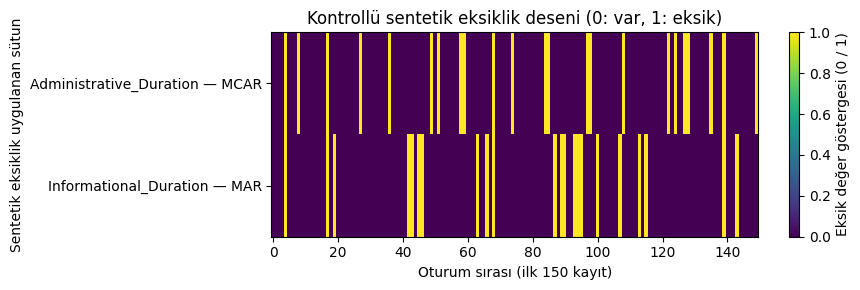

Grafik yorumu: Desen yalnızca yapay deneyde eklenen eksikleri gösterir.

=== C: EKSİKLİK GÖSTERGESİ KARŞILAŞTIRMASI ===


,add_indicator,balanced_accuracy ortalama,balanced_accuracy std,average_precision ortalama,average_precision std
0,False,0.8124,0.0123,0.6500,0.0248
1,True,0.8118,0.0121,0.6499,0.0250


Her iki model için 5 kat × 2 tekrar = 10 doğrulama skoru karşılaştırıldı.
Ölçütler: dengeli doğruluk ve average precision (PR-AUC özeti).
NOT: Bu deney yapay eksiklik üzerindedir; gerçek veri seti eksiksizdir.


In [ ]:
# BÖLÜM 1.3 — GERÇEK EKSİKLİK DENETİMİ VE AYRI SENTETİK DENEY
# Orijinal X, y, df üzerinde değişiklik YAPILMAZ.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

# (A) Gerçek verinin eksiklik ve eksik-kodu denetimi
print("=== A: GERÇEK VERİ DENETİMİ ===")
print("Gerçek NaN hücre sayısı:", int(X.isna().sum().sum()))
missing_tokens = {"?", "NA", "N/A", "NULL", "null", "", " "}
token_counts = {col: int(X[col].astype(str).str.strip().isin(missing_tokens).sum())
                for col in X.columns}
print("Kontrol edilen özel eksik belirteçlerin toplam sayısı:", sum(token_counts.values()))
print("Eksik belirteç bulunan sütunlar:",
      {k: v for k, v in token_counts.items() if v > 0})
print("NOT: Sayısal sıfırlar otomatik olarak eksik kabul EDİLMEDİ.")

# (B) Kontrollü ve şeffaf sentetik eksiklik oluşturma
print("\n=== B: YALNIZCA DENEY İÇİN SENTETİK EKSİKLİK ===")
rng = np.random.default_rng(SEED)
X_missing_sim = X.copy(deep=True)

# MCAR: Administrative_Duration için tüm satırlarda sabit eksiklik olasılığı
mcar_mask = rng.random(len(X_missing_sim)) < 0.15
X_missing_sim.loc[mcar_mask, "Administrative_Duration"] = np.nan

# MAR: Informational_Duration eksikliği, gözlenen ProductRelated'e bağlı
mar_probability = np.where(X["ProductRelated"].to_numpy() >= 10, 0.30, 0.05)
mar_mask = rng.random(len(X_missing_sim)) < mar_probability
X_missing_sim.loc[mar_mask, "Informational_Duration"] = np.nan

sim_missing_percent = (X_missing_sim.isna().mean() * 100).round(2)
display(sim_missing_percent[sim_missing_percent > 0]
        .rename("Sentetik eksiklik (%)").to_frame())
print("MCAR gerçekleşen kayıt sayısı:", int(mcar_mask.sum()))
print("MAR gerçekleşen kayıt sayısı:", int(mar_mask.sum()))
print("Orijinal X tablosunda eksiklik yine:", int(X.isna().sum().sum()))

# Eksiklik desenini ilk 150 oturum için görselleştirme
mask_view = X_missing_sim[
    ["Administrative_Duration", "Informational_Duration"]
].isna().iloc[:150].T
fig, ax = plt.subplots(figsize=(9, 3))
im = ax.imshow(mask_view.to_numpy(), aspect="auto", interpolation="nearest",
               vmin=0, vmax=1)
ax.set_yticks([0, 1])
ax.set_yticklabels(["Administrative_Duration — MCAR",
                    "Informational_Duration — MAR"])
ax.set_xlabel("Oturum sırası (ilk 150 kayıt)")
ax.set_ylabel("Sentetik eksiklik uygulanan sütun")
ax.set_title("Kontrollü sentetik eksiklik deseni (0: var, 1: eksik)")
fig.colorbar(im, ax=ax, label="Eksik değer göstergesi (0 / 1)")
fig.tight_layout()
plt.show()
print("Grafik yorumu: Desen yalnızca yapay deneyde eklenen eksikleri gösterir.")

# (C) add_indicator=False / True karşılaştırması
print("\n=== C: EKSİKLİK GÖSTERGESİ KARŞILAŞTIRMASI ===")
categorical_columns = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]
numeric_columns = [c for c in X.columns if c not in categorical_columns]

def make_missingness_pipeline(add_indicator):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median",
                                  add_indicator=add_indicator)),
        ("scaler", StandardScaler())
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])
    preprocessing = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns)
    ])
    return Pipeline([
        ("preprocessing", preprocessing),
        ("classifier", LogisticRegression(
            class_weight="balanced", max_iter=2000, random_state=SEED
        ))
    ])

cv_missingness = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=2, random_state=SEED
)
metric_names = {
    "balanced_accuracy": "balanced_accuracy",
    "average_precision": "average_precision"
}
cv_rows = []
for indicator_setting in [False, True]:
    model = make_missingness_pipeline(indicator_setting)
    scores = cross_validate(
        model, X_missing_sim, y, cv=cv_missingness,
        scoring=metric_names, n_jobs=1, error_score="raise"
    )
    row = {"add_indicator": indicator_setting}
    for metric in metric_names:
        vals = scores[f"test_{metric}"]
        row[f"{metric} ortalama"] = round(float(np.mean(vals)), 4)
        row[f"{metric} std"] = round(float(np.std(vals, ddof=1)), 4)
    cv_rows.append(row)

missing_indicator_results = pd.DataFrame(cv_rows)
display(missing_indicator_results)
print("Her iki model için 5 kat × 2 tekrar = 10 doğrulama skoru karşılaştırıldı.")
print("Ölçütler: dengeli doğruluk ve average precision (PR-AUC özeti).")
print("NOT: Bu deney yapay eksiklik üzerindedir; gerçek veri seti eksiksizdir.")


**Yorum — 1.3 Eksiklik analizi (Colab'da doğrulanmıştır)**

**Gerçek veri:** 17 girdi özelliğinin tamamında gerçek eksik hücre sayısı **0**'dır. Özel eksik belirteçlerin taramasında da **0** bulundu. Sıfır değerleri gerçek ölçümler olarak korundu.

**Yapay eksiklik deneyi:** Orijinal veri değiştirilmedi. Sadece deney kopyasında `Administrative_Duration` için MCAR yaklaşımıyla **1.849 gözlem (%15,0)**, `Informational_Duration` için `ProductRelated` değişkeniyle bağlantılı MAR yaklaşımıyla **2.688 gözlem (%21,8)** eksik bırakıldı. Görsel, yalnızca yapay eksiklik desenini göstermektedir. Gerçek veride MCAR, MAR veya MNAR mekanizması bulunduğu ileri sürülemez.

**Modellerin karşılaştırılması (5 kat × 2 tekrar):**

| Yöntem | Balanced accuracy (ortalama ± ss) | Average precision (ortalama ± ss) |
|---|---|---|
| `add_indicator=False` | **0,8124 ± 0,0123** | **0,6500 ± 0,0248** |
| `add_indicator=True` | **0,8118 ± 0,0121** | **0,6499 ± 0,0250** |

Eksiklik göstergesiyle dengeli doğrulukta **0,0006**, average precision'da **0,0001** düşüş gözlendi. Bu küçük farklar yapay deneyimizde ek göstergenin pratik faydasına kanıt sunmamaktadır. Ancak istatistiksel anlamlılık testi yapılmadığından anlamlılık hakkında kesin hüküm kurulamaz.

**Yöntem:** Eksiklik maskesi hedef değişkenden bağımsız olarak üretildi. İmputasyon, kodlama ve ölçekleme modellerin `Pipeline` içinde ve yalnızca eğitim katlarından öğrenildi. Sonuçlar ana veri setinde gerçek eksiklik bulunduğuna veya ana sınıflandırma modelinin başarısına kanıt olarak kullanılmaz. MNAR, eksikliğin gözlenmeyen değere bağlı olduğu mekanizma olarak kavramsal düzeyde açıklanmıştır.


### 1.4 Kategorik kodlama — One-hot, nadir kategori birleştirme ve hedef kodlama

`TrafficType`, **20 kategorisi** olan, sayısal saklanan fakat nominal bir değişkendir. Kıyaslama:

1. One-hot kodlama: trafik türü başına gösterge sütunu.
2. Nadir kategori birleştirme: eğitim katında frekansı %1'den az kategorileri tek nadir kategoride ele alan one-hot kodlama.
3. Kat dışı hedef kodlama: `TargetEncoder` ile eğitim verisi içinde çapraz kodlama ve dış değerlendirme katlarını hiç kullanmama.
4. **Bilerek yanlış** hedef kodlama: tüm veride hedef ortalaması hesaplayıp dış çapraz doğrulamaya girme. Bu, değerlendirme etiketlerini ön işlemeye sızdırdığı için geçersiz deneydir.

Aynı lojistik regresyon, aynı 5 kat × 2 tekrar ve `balanced_accuracy` ile `average_precision` ölçütleri kullanılır. Doğru yöntemlerin bütün dönüşümleri `Pipeline` içinde gerçekleştirilir. Yanlış yöntemin skoru model seçiminde kullanılmayacak, veri sızıntısının neden hatalı olduğu anlatılacaktır.


=== 1.4 TRAFİK TÜRÜ KATEGORİLERİ ===
TrafficType farklı kategori sayısı: 20


,Oturum sayısı
TrafficType,
2,3913
1,2451
3,2052
4,1069
13,738
10,450
6,444
8,343
5,260


Oranı %1'den düşük kategoriler: [9, 7, 15, 19, 14, 18, 16, 12, 17]

=== DOĞRU HATLAR ===

=== BİLEREK HATALI HAT — sadece gösterim ===


,Kodlama,balanced_accuracy ort,balanced_accuracy std,average_precision ort,average_precision std
0,One-hot,0.8126,0.0122,0.6499,0.0245
1,One-hot + nadir (%1),0.8135,0.0127,0.6502,0.0247
2,Kat dışı hedef kodlama,0.8138,0.0111,0.6515,0.0246
3,YANLIŞ: global hedef kodlama,0.8138,0.0113,0.6518,0.0245


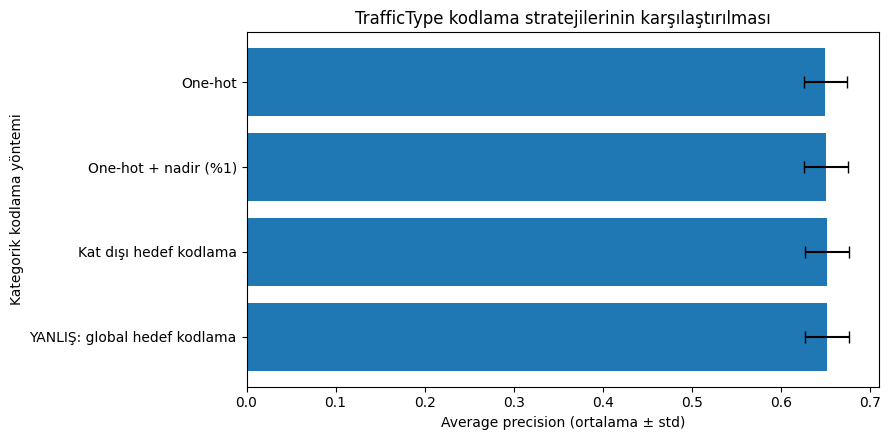

Grafik yorumu: Hata çubukları çapraz doğrulama skorlarının standart sapmasıdır.
UYARI: 'YANLIŞ: global hedef kodlama' geçersizdir; model seçimine katılmaz.


In [6]:
# BÖLÜM 1.4 — KATEGORİK KODLAMA VE KONTROLLÜ SIZINTI GÖSTERİMİ
# X, y ve df değiştirilmez.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

print("=== 1.4 TRAFİK TÜRÜ KATEGORİLERİ ===")
print("TrafficType farklı kategori sayısı:", X["TrafficType"].nunique())
display(X["TrafficType"].value_counts().rename("Oturum sayısı").to_frame())
rare_levels = X["TrafficType"].value_counts(normalize=True)
print("Oranı %1'den düşük kategoriler:", rare_levels[rare_levels < .01].index.tolist())

categorical_cols = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]
other_categorical_cols = [c for c in categorical_cols if c != "TrafficType"]
numeric_cols = [c for c in X.columns if c not in categorical_cols]

def make_encoder_model(traffic_encoder=None, leaky=False):
    numeric_input_cols = numeric_cols + (["TrafficType_TE_global"] if leaky else [])
    transformers = [
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_input_cols),
        ("other_categorical", OneHotEncoder(handle_unknown="ignore"), other_categorical_cols)
    ]
    if not leaky:
        transformers.append(("traffic", traffic_encoder, ["TrafficType"]))
    prep = ColumnTransformer(transformers)
    return Pipeline([
        ("prep", prep),
        ("model", LogisticRegression(
            class_weight="balanced", random_state=SEED, max_iter=2000
        ))
    ])

cv_encoding = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
metrics = {"balanced_accuracy": "balanced_accuracy",
           "average_precision": "average_precision"}
rows = []

def evaluate_encoding(name, model, features):
    scores = cross_validate(
        model, features, y, cv=cv_encoding, scoring=metrics,
        n_jobs=1, error_score="raise"
    )
    result = {"Kodlama": name}
    for key in metrics:
        vals = scores["test_" + key]
        result[key + " ort"] = float(vals.mean())
        result[key + " std"] = float(vals.std(ddof=1))
    rows.append(result)

print("\n=== DOĞRU HATLAR ===")
evaluate_encoding("One-hot",
                  make_encoder_model(OneHotEncoder(handle_unknown="ignore")), X)
evaluate_encoding("One-hot + nadir (%1)",
                  make_encoder_model(OneHotEncoder(
                      handle_unknown="infrequent_if_exist", min_frequency=0.01
                  )), X)
evaluate_encoding("Kat dışı hedef kodlama",
                  make_encoder_model(TargetEncoder(
                      target_type="binary", smooth="auto", cv=5,
                      shuffle=True, random_state=SEED
                  )), X)

# YANLIŞ: Tüm veriyle hedef kodlaması dış CV'den önce öğreniliyor.
# Bu, doğrulama etiketlerini dönüşüme sızdıran geçersiz düzenektir.
print("\n=== BİLEREK HATALI HAT — sadece gösterim ===")
global_target_encoder = TargetEncoder(
    target_type="binary", smooth="auto", cv=5,
    shuffle=True, random_state=SEED
)
global_encoded_traffic = global_target_encoder.fit(
    X[["TrafficType"]], y
).transform(X[["TrafficType"]])[:, 0]
X_leaky = X.drop(columns="TrafficType").copy()
X_leaky["TrafficType_TE_global"] = global_encoded_traffic
evaluate_encoding("YANLIŞ: global hedef kodlama", make_encoder_model(leaky=True), X_leaky)

encoding_results = pd.DataFrame(rows)
for col in encoding_results.columns:
    if col != "Kodlama":
        encoding_results[col] = encoding_results[col].round(4)
display(encoding_results)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(encoding_results["Kodlama"], encoding_results["average_precision ort"],
        xerr=encoding_results["average_precision std"], capsize=4)
ax.invert_yaxis()
ax.set_xlabel("Average precision (ortalama ± std)")
ax.set_ylabel("Kategorik kodlama yöntemi")
ax.set_title("TrafficType kodlama stratejilerinin karşılaştırılması")
fig.tight_layout()
plt.show()
print("Grafik yorumu: Hata çubukları çapraz doğrulama skorlarının standart sapmasıdır.")
print("UYARI: 'YANLIŞ: global hedef kodlama' geçersizdir; model seçimine katılmaz.")


**Yorum — 1.4 Kategorik kodlama (Colab'da çalıştırılarak doğrulanmıştır)**

`TrafficType` **20 farklı nominal kategoriden** oluşur; sayısal olarak saklanan kodlar büyüklük sırası ifade etmez. Trafik türlerinin **9 kategorisinde frekans %1'in altındadır** (9, 7, 15, 19, 14, 18, 16, 12, 17). Nadir kategoriler için farklı kodlama seçenekleri aynı deney hattında incelenmiştir.

**Aynı 5 kat × 2 tekrarlı katmanlı çapraz doğrulama ile model sonuçları:**

| Kodlama yöntemi | Balanced accuracy (ortalama ± ss) | Average precision (ortalama ± ss) | Geçerli mi? |
|---|---:|---:|---|
| One-hot | 0,8126 ± 0,0122 | 0,6499 ± 0,0245 | Evet |
| One-hot + nadir kategori (%1) | 0,8135 ± 0,0127 | 0,6502 ± 0,0247 | Evet |
| Kat dışı hedef kodlama | **0,8138 ± 0,0111** | **0,6515 ± 0,0246** | Evet |
| **YANLIŞ:** Global hedef kodlama | 0,8138 ± 0,0113 | 0,6518 ± 0,0245 | **Hayır** |

Üç geçerli yöntem arasında kat dışı hedef kodlama en yüksek ortalama skorları vermiştir; ancak **one-hot'a göre balanced accuracy farkı yalnızca +0,0012, average precision farkı +0,0016** düzeyindedir. Bu küçük farklardan tek başına istatistiksel üstünlük sonucu çıkarılamaz. Nadir kategorileri birleştirmek de bu deneyde yalnızca küçük bir değişim sağlamıştır.

**Bilerek yanlış kurulumun sınırı:** Global hedef kodlama `TrafficType` sınıf ortalamalarını **tüm hedef etiketlerinden** öğrenir; dış doğrulama katlarının hedefleri de bu ortalamalara karışır. Bu nedenle sonuç değerlendirme açısından **geçersizdir**. Yanlış global kodlama ile doğru kat dışı kodlamanın average precision ortalamaları arasındaki fark **+0,0003** olsa da bunun gerçek iyileşme olarak sunulması uygun değildir. Benzer skorların elde edilmesi veri sızıntısını meşru kılmaz.

**Karar:** İlk değerlendirmede kat dışı hedef kodlama küçük bir ortalama avantaja sahiptir; yöntemlerin kararlılığı, basitliği ve diğer modellerdeki uyumu incelenmeden kesin bir model/ön işleme tercihi ilan edilmeyecektir. Tüm geçerli dönüşümler `Pipeline` içinde öğrenilmeye devam edecektir. Tekrarlanan 125 girdinin olası etkisi daha sonraki değerlendirmede ayrıca ele alınmalıdır.


### 1.5 Veri sızıntısı deneyi — hatalı ve doğru değerlendirme düzenekleri

Bu deneyin amacı **aynı ön işleme ve aynı modeli** iki farklı sırayla çalıştırmaktır:

- **Yanlış düzenek:** Ön işleme **ve hedefe bağlı öznitelik seçimi** bütün veri üzerinde öğrenilir; sonra çapraz doğrulama yapılır. Bu, doğrulama katının özelliklerini ve özellikle **etiketlerini** seçime sızdırır.
- **Doğru düzenek:** Eksik değer doldurma, ölçekleme, kategorik kodlama ve hedefe bağlı öznitelik seçimi `Pipeline` içine yerleştirilir. Her katın dönüştürücüleri yalnızca o katın **eğitim parçasında** öğrenilir.

**Sabit tasarım:** `SelectKBest(f_classif, k=10)` ve `LogisticRegression(class_weight="balanced")`; her iki düzenekte aynı **5 kat × 2 tekrar**, aynı rastgele tohum ve **balanced accuracy + average precision** ölçütleri kullanılır. Ortalama ± standart sapma, hata çubukları ve kat bazında iki kurulumun farkları raporlanır.

**Önemli:** Yanlış kurulum yalnızca öğretici karşılaştırmadır, model seçiminde kullanılamaz. Sızıntı olması her zaman çok büyük bir skor farkına neden olmak zorunda değildir; veri ve seçilen özelliklerin yapısı farkı etkileyebilir. Ayrıca bu deney, 125 yinelenen girdinin çapraz katlara dağılımı sorununu tek başına çözmez.


In [ ]:
# BÖLÜM 1.5 — KONTROLLÜ VERİ SIZINTISI DENEYİ
# Aynı özellikler, seçim metodu, model ve CV katları; yalnızca işlem sırası farklı.
# Orijinal X, y ve df DEĞİŞTİRİLMEZ.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("=== 1.5 ÖN İŞLEME + HEDEFE BAĞLI SEÇİM: DOĞRU / YANLIŞ ===")
category_cols_15 = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]
numeric_cols_15 = [c for c in X.columns if c not in category_cols_15]

def make_preprocessor_15():
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_cols_15),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         category_cols_15)
    ])

def make_classifier_15():
    return LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=SEED
    )

# CV indeksleri bir kez oluşturulup iki yöntem için birebir aynı tutulur.
cv_15 = list(RepeatedStratifiedKFold(
    n_splits=5, n_repeats=2, random_state=SEED
).split(X, y))
metrics_15 = {
    "balanced_accuracy": "balanced_accuracy",
    "average_precision": "average_precision"
}

# DOĞRU: tüm dönüşümler yalnızca eğitim katında öğrenilir.
correct_pipeline_15 = Pipeline([
    ("preprocessing", make_preprocessor_15()),
    ("selection", SelectKBest(score_func=f_classif, k=10)),
    ("model", make_classifier_15())
])
correct_scores_15 = cross_validate(
    correct_pipeline_15, X, y, cv=cv_15, scoring=metrics_15,
    n_jobs=1, error_score="raise"
)

# YANLIŞ: doğrulama katları daha oluşturulmadan veri+etiketle seçim yapılır.
# Gerçek model değerlendirmesi için kesinlikle kullanılmamalıdır.
wrong_preprocessor_15 = make_preprocessor_15()
X_all_preprocessed_15 = wrong_preprocessor_15.fit_transform(X)
wrong_selector_15 = SelectKBest(score_func=f_classif, k=10)
X_all_selected_15 = wrong_selector_15.fit_transform(X_all_preprocessed_15, y)
wrong_scores_15 = cross_validate(
    make_classifier_15(), X_all_selected_15, y,
    cv=cv_15, scoring=metrics_15, n_jobs=1, error_score="raise"
)

# Her metrik için 10 katın ortalaması ve örnek standart sapması
rows_15 = []
for label, scores in [
    ("Doğru: Pipeline içinde", correct_scores_15),
    ("YANLIŞ: tüm veride seçim", wrong_scores_15)
]:
    row = {"Kurulum": label}
    for metric in metrics_15:
        v = scores["test_" + metric]
        row[metric + " ort"] = round(float(np.mean(v)), 4)
        row[metric + " std"] = round(float(np.std(v, ddof=1)), 4)
    rows_15.append(row)
leakage_results_15 = pd.DataFrame(rows_15)
display(leakage_results_15)

# Aynı katlardaki farkları ayrıca göster (yanlış - doğru)
paired_differences_15 = {}
for metric in metrics_15:
    gap = wrong_scores_15["test_" + metric] - correct_scores_15["test_" + metric]
    paired_differences_15[metric] = gap
    print(f"{metric}: yanlış - doğru = {gap.mean():+.4f} (ortalama), "
          f"ss={gap.std(ddof=1):.4f}; 10 katın {int((gap>0).sum())}'unda yanlış daha yüksek")

# Ortalama + standart sapma hata çubuklarıyla iki metrik için karşılaştırma
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, metric, title in zip(
    axes, metrics_15, ["Balanced accuracy", "Average precision"]
):
    v = leakage_results_15[metric + " ort"].to_numpy()
    sd = leakage_results_15[metric + " std"].to_numpy()
    ax.barh(leakage_results_15["Kurulum"], v, xerr=sd, capsize=4)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("Ortalama ± standart sapma")
    ax.set_title(title)
fig.suptitle("Veri sızıntısı deneyi: geçerli ve geçersiz değerlendirme")
fig.tight_layout()
plt.show()
print("Grafik yorumu: Aynı CV katlarında ön işlemenin sırası karşılaştırıldı.")
print("UYARI: YANLIŞ kurulumun skorları nihai model seçimi için kullanılamaz.")


**Yorum — 1.5 Veri sızıntısı deneyi (Colab çıktıları beklenecek)**

- **Doğru kurulum:** Tüm ön işleme ve denetimli `SelectKBest` seçimi `Pipeline` içinde yalnızca eğitim katlarında öğrenilir.
- **Yanlış kurulum:** `SelectKBest` dahil bütün veri üzerinde ön işleme uygulanır; doğrulama etiketleri kullanıldığı için skor geçersizdir.
- **Doğru kurulum balanced accuracy:** **[ÇIKTIDAN ortalama ± ss]**; **average precision:** **[ÇIKTIDAN ortalama ± ss]**.
- **Yanlış kurulum balanced accuracy:** **[ÇIKTIDAN ortalama ± ss]**; **average precision:** **[ÇIKTIDAN ortalama ± ss]**.
- **Gözlenen fark (yanlış − doğru):** **[ÇIKTIDAN DOLDUR]**. Hatalı kurulum daha yüksek, benzer veya daha düşük skor verse bile model seçimine alınamaz; sızıntının varlığı işlem sırasıyla ilgilidir.
- **Sınırlılıklar:** Bunlar 10 tekrarlı CV skorudur; tam bağımsız bir dış test verisinin kanıtı değildir. Yinelenen kayıtların bölümlemeye etkisi ayrıca incelenmelidir.


### 1.6 Baseline ve ilk model
`DummyClassifier` ve tek bir basit model, sızıntısız hat içinde.

In [ ]:
from sklearn.dummy import DummyClassifier

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 1.7 Weka ile bağımsız kontrol
ZeroR ve J48, 10 kat çapraz doğrulama; çıktıyı yapıştırın ve Python ile tutarlılığını yorumlayın.

In [ ]:
weka_cikti = """

"""

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Bölüm 2 · Sınıflandırma ve dürüst model değerlendirme *(ağırlık 30)*
**Makale:** Dietterich (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7).

**Okuma notu (3–4 cümle):** …

### 2.1 Model karşılaştırması
Baseline, karar ağacı, k-NN, rastgele orman, gradyan artırma; tekrarlı katmanlı ÇD; ortalama ± std tablosu ve kutu grafiği; ölçüt seçiminin gerekçesi.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.2 Karar ağacının yorumu
`export_text` ile kök ve ilk iki düzeyin alan bilgisiyle yorumu.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.3 Optimist yanlılık
`GridSearchCV.best_score_` ile iç içe ÇD skorunun karşılaştırması.

In [ ]:
from sklearn.model_selection import GridSearchCV

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.4 İstatistiksel test
En iyi iki modelin farkı: McNemar ya da 5×2 ÇD t-testi. "Fark anlamlı çıkmadı" tam puanlık bir sonuçtur.

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.5 Proje 2'ye aktarılacak model ve çıktılar
En iyi modeli ve protokolü gerekçesiyle seçin; temizlenmiş veriyi ve hattı kaydedin.

In [ ]:
# import joblib
# df_temiz.to_csv("p1_temiz_veri.csv", index=False)
# joblib.dump(hat, "p1_hat.joblib")

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Bölüm 3 · Veri küpü ve birliktelik analizi *(ağırlık 15)*
**Makale:** Wu, Chen ve Han (2010). Re-examination of interestingness measures in pattern mining. *Data Mining and Knowledge Discovery*, 21(3).

**Okuma notu (3–4 cümle):** …

### 3.1 Kısa veri küpü
Bir olgu ve en az üç boyut; roll-up ve drill-down; toplamdaki bir eğilimin alt gruplarda değişip değişmediği (Simpson paradoksu).

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 3.2 Birliktelik: seçenek ve kurulum
İşlem bilgisi varsa **A**, yoksa **B**. Veri değiştirilmez.

**Seçenek:** …

In [ ]:
!pip -q install mlxtend
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 3.3 Kurallar ve ilgi ölçütleri
**A:** işlem tanımı; Apriori ve FP-Growth, en az üç `min_support`; güven, lift ve Kulczynski; null-invariance testi.
**B:** ayrıklaştırma ve "öznitelik = değer" işlemleri; hedefe yönelik kurallar; lift ve Kulczynski; Proje 1 modelinin önemli öznitelikleriyle karşılaştırma.
İki seçenekte de üç kuralın alan bilgisiyle yorumu.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 3.4 Weka ile kontrol
Aynı eşiklerde Weka Apriori çıktısı.

In [ ]:
weka_apriori = """

"""

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

## Varsayım defteri
Bu ödevde verdiğiniz her kararı ve gerekçesini madde madde yazın (ön işleme, ölçüt, eşik, parametre, veri seçimi). En az bir kararın ödev makalesine dayandığını belirtin.

- **Karar:** … — **Gerekçe:** …
- **Karar:** … — **Gerekçe:** …

## Katkı beyanı (zorunlu)

Bu çalışma **tek kişi** tarafından yürütülmektedir. Öğrenci: **[AD SOYAD — DOLDURULACAK]**.

- **Bölüm 1 (1.1–1.7):** [Gerçekleştirilen kod, analiz ve yorumlar tamamlandıktan sonra somutlaştırılacak]
- **Bölüm 2 (2.1–2.5):** [Gerçek katkılar tamamlandıktan sonra yazılacak]
- **Bölüm 3 (3.1–3.4):** [Gerçek katkılar tamamlandıktan sonra yazılacak]
- **Sunum:** [Anlatılacak alt başlıklar ve hazırlık]

GitHub commit geçmişiyle ve yapılan çalışmalarla tutarlı biçimde güncellenecektir.


## Yapay zekâ beyanı

ChatGPT, yönergenin yorumlanması, bireysel çalışma kapsamının belirlenmesi, GitHub README dosyasının hazırlanması, öğretim üyesinin Colab şablonunun tek kişilik kullanıma uyarlanması ve UCI veri yükleme kodunun taslağı için kullanılmıştır. **Model deneyleri henüz çalıştırılmamıştır.** Sonraki yapay zekâ kullanımları ve insan tarafından yapılan doğrulamalar çalışma ilerledikçe buraya eklenecektir.


## Kaynaklar

- [UCI Online Shoppers Purchasing Intention Dataset](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)
- Sakar & Kastro (2018). *Online Shoppers Purchasing Intention Dataset*. https://doi.org/10.24432/C5F88Q
- Kaufman vd. (2012). *Leakage in data mining: Formulation, detection, and avoidance*.
- Dietterich (1998). *Approximate statistical tests for comparing supervised classification learning algorithms*.
- Wu, Chen ve Han (2010). *Re-examination of interestingness measures in pattern mining*.
